In [6]:
#importing necessary FrameWorks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Load dataset
df = pd.read_csv(r"C:\Users\User\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\CD536E1642B8B31EAFA40258D5B9D9A40C3F670E\transfers\2026-44\Exam_Datasets\Exam_Dataset\POP.csv")

In [8]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       229 non-null    str    
 1   Population 2022  220 non-null    str    
 2   Unnamed: 2       0 non-null      float64
 3   Unnamed: 3       230 non-null    str    
 4   Unnamed: 4       230 non-null    str    
 5   Unnamed: 5       2 non-null      str    
dtypes: float64(1), str(5)
memory usage: 20.9 KB


In [9]:
# Number of rows and columns
print("Dataset dimensions:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset dimensions: (328, 6)
Number of rows: 328
Number of columns: 6


In [10]:
# Inspect data types
df.dtypes

Unnamed: 0             str
Population 2022        str
Unnamed: 2         float64
Unnamed: 3             str
Unnamed: 4             str
Unnamed: 5             str
dtype: object

In [12]:
# Count missing values
df.isnull().sum()

Unnamed: 0          99
Population 2022    108
Unnamed: 2         328
Unnamed: 3          98
Unnamed: 4          98
Unnamed: 5         326
dtype: int64

In [13]:
# Count duplicate rows
"Number of duplicate rows:", df.duplicated().sum()
df[df.duplicated()]

,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
1,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
221,NaN,NaN,NaN,NaN,NaN,NaN
222,NaN,NaN,NaN,NaN,NaN,NaN
224,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
323,NaN,NaN,NaN,NaN,NaN,NaN
324,NaN,NaN,NaN,NaN,NaN,NaN
325,NaN,NaN,NaN,NaN,NaN,NaN
326,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
#filling all missing values
df = df.fillna({col: 'Unknown' if df[col].dtype == 'object' else 0 for col in df.columns})

In [15]:
#checking if missing values has been handles
(df.isnull().sum())

Unnamed: 0         0
Population 2022    0
Unnamed: 2         0
Unnamed: 3         0
Unnamed: 4         0
Unnamed: 5         0
dtype: int64

In [16]:
#reading the first five rows to idendfy dublicates
df.head(5)

,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,0,0,0.0,0,0,0
1,0,0,0.0,0,0,0
2,0,Ranking,0.0,Economy,(thousands),0
3,0,0,0.0,0,0,0
4,IND,1,0.0,India,"1,417,173",0


In [17]:
#Remove the first 4 rows which are empty 
df_clean = df.iloc[4:].copy()

In [18]:
#column cleaning
df_clean = df_clean.iloc[:, [0, 2, 3, 4]]

In [19]:
#Renaming the remaining columns to clean, proper names
df_clean.columns = ['Country_Code', 'Ranking', 'Country', 'Population']


In [20]:
#Cleaning the Population column (removing commas and convert to numbers)
df_clean['Population'] = df_clean['Population'].astype(str).str.replace(',', '')
df_clean['Population'] = pd.to_numeric(df_clean['Population'], errors='coerce')

In [21]:
#Resetting to starts from 0
df_clean = df_clean.reset_index(drop=True)

In [22]:
# Display the result
display(df_clean.head())

,Country_Code,Ranking,Country,Population
0,IND,0.0,India,1417173
1,CHN,0.0,China,1412175
2,USA,0.0,United States,333288
3,IDN,0.0,Indonesia,275501
4,PAK,0.0,Pakistan,235825


In [34]:
#ranking top trending countries
top_5_countries = (df_clean.nlargest(5, 'Population')['Country'].tolist())

print(top_5_countries)

['World', 'Lower middle income', 'Upper middle income', 'East Asia & Pacific', 'South Asia']


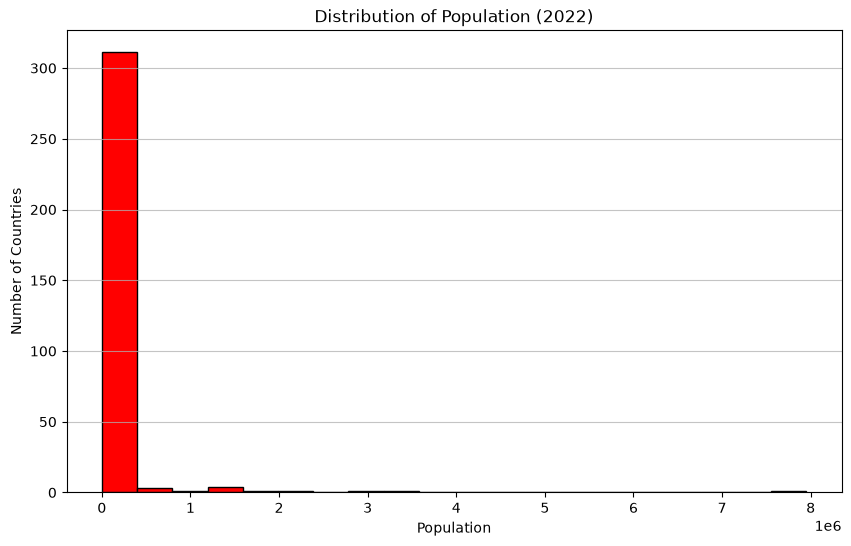

In [42]:
# Setting the figure size for better readability
plt.figure(figsize=(10, 6))
# Create the histogram using the 'Population' column
plt.hist(df_clean['Population'], bins=20, color='red', edgecolor='black')

# Add a title and labels
plt.title('Distribution of Population (2022)')
plt.xlabel('Population')
plt.ylabel('Number of Countries')

# Add a grid to make it easier to read
plt.grid(axis='y', alpha=0.75)

# Show the plot
plt.show()

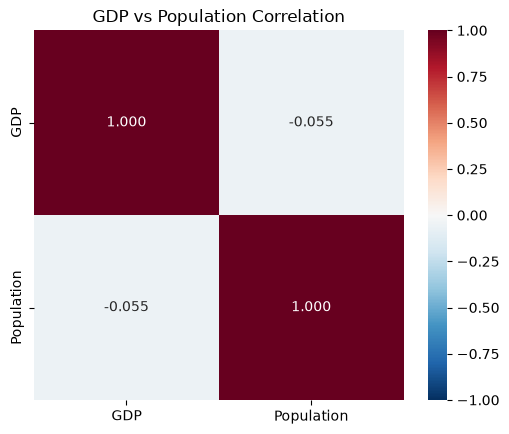

In [46]:
# heatmap c
subset = data[['GDP', 'Population']]
sns.heatmap(subset.corr(), annot=True, cmap='RdBu_r', 
            vmin=-1, vmax=1, fmt='.3f', square=True)
plt.title('GDP vs Population Correlation')
plt.show()